# The rock factor: where the one free number of the classical equation comes from

**Level 2: The method in practice** · Needs: 02-classical-prediction/01-the-classical-equation-on-one-blast · Reading time: about 25 minutes

## Objectives

Both source papers say the rock factor `A` "was estimated for each blast", and neither prints a value. Without it the classical equation cannot run. This notebook shows the two ways the engine can obtain one: from a published rating table, and by inverting the equation on a published prediction. It then asks which of them survives contact with the data.

By the end you will have:

- recovered the rock factor of every site by inverting the equation on the published predictions, and reproduced the engine's pinned table;
- measured how much the recovered factor varies inside a site (which tests the geometry) and between sites (which is the rock);
- run the three published rating schemes for the Akdaglar rock and compared them with the recovered value.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

This cell imports nothing from the notebook yet: it reads the installed versions from the package metadata and prints them, so the output records exactly which engine produced every number below.

In [1]:
# Print the installed version of every package this notebook uses
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The hold-out blasts with the classical column each paper prints | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957; Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 | numeric facts reused with citation; the articles never ship | `bf.load_holdout()` inside the `blastfrag` wheel |
| The rock description of each site (strength, density, modulus) | the same articles, as carried in the committed benchmark | numeric facts reused with citation | `data/derived/benchmark.json`, field `site_meta` |
| The rating tables | Hudaverdi et al. 2010 Eqs. 2 and 3; Babaeian et al. 2019, https://doi.org/10.1016/j.jrmge.2018.11.006 (Tables 1 and 2) | the tables are reproduced with citation | `bf.rock_factor` and `bf.SCHEMES` in the engine |

## Method

**Route 1, a rating table.** Lilly's blastability index is the sum of five ratings (rock mass description, joint spacing, joint plane orientation, a density term and a strength term), and the rock factor is 0.06 times the index (Hudaverdi et al. 2010, https://doi.org/10.1002/nag.957, Eqs. 2 and 3). Babaeian et al. 2019 (https://doi.org/10.1016/j.jrmge.2018.11.006) print the same sum with a different strength term and different rating tables, and tabulate a third, five-band lookup by Hustrulid.

**Route 2, inversion.** The equation of the previous notebook is linear in `A`, so a published prediction `x50_pub` for a blast with known `V` and `Q` fixes it:

```
A = x50_pub / [ (V / Q)^0.8 * Q^(1/6) * (RWS / 115)^(-19/30) ]
```

The recovered value is only worth trusting if it is nearly the same for every blast of one site, because the rock does not change inside a campaign. That constancy is also a test of the geometry reconstruction: an error in burden or bench height would scatter the factor.

### Step 1: the published column

The engine ships the two hold-out sets with, for each blast, the classical prediction each paper printed. The cell lists those columns and how many blasts of each have a resolvable geometry (inversion needs `V` and `Q`).

In [2]:
# Imports, then the union of the two published hold-outs and the prediction columns each blast carries
import json
import re
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

DERIVED = Path("../../../data/derived")
holdout = bf.load_holdout(protocol="union")
print("blasts in the union of the hold-outs:", len(holdout))
print("published columns of the first blast:", sorted(holdout[0].meta["published"]))
with_geometry = [b for b in holdout if bf.has_absolute_geometry(b)]
for column in ("kuzram_2010", "kuzram_2012"):
    n = sum(1 for b in with_geometry if b.meta["published"].get(column) is not None)
    print(f"{column}: {n} blasts with a printed value and a resolvable geometry")

blasts in the union of the hold-outs: 14
published columns of the first blast: ['kuzram_2010', 'kuzram_2012', 'nn_mean_2012', 'regression_2010', 'regression_2012']
kuzram_2010: 12 blasts with a printed value and a resolvable geometry
kuzram_2012: 12 blasts with a printed value and a resolvable geometry


### Step 2: invert the equation on every blast

For each hold-out blast the cell reconstructs the pattern, takes `V` and `Q`, and calls `back_solve_rock_factor` with the 2012 printed prediction. It then groups the recovered values by site and reports the mean and the relative spread (maximum minus minimum over the mean).

In [3]:
# Back-solve the rock factor of every hold-out blast from its published 2012 prediction
per_site = {}
for blast in with_geometry:
    published = blast.meta["published"].get("kuzram_2012")
    if published is None:
        continue
    pattern = bf.reconstruct_pattern(blast)
    factor = bf.back_solve_rock_factor(published, rock_volume_m3=pattern.rock_volume_m3, charge_mass_kg=pattern.charge_mass_kg)
    per_site.setdefault(blast.site, []).append(factor)

print(f"{'site':<14}{'n':>3}{'mean A':>10}{'spread':>12}   pinned in the engine")
for site, values in sorted(per_site.items()):
    mean = sum(values) / len(values)
    spread = (max(values) - min(values)) / mean
    print(f"{site:<14}{len(values):>3}{mean:>10.2f}{spread:>11.1%}   {bf.SITE_ROCK_FACTOR[site]}")
agree = all(round(sum(v) / len(v), 2) == bf.SITE_ROCK_FACTOR[s] for s, v in per_site.items())
print("recomputed table equals the pinned table to two decimals:", agree)

site            n    mean A      spread   pinned in the engine
Akdaglar        2      6.72       3.7%   6.72
Dongri-Buzurg   1      3.68       0.0%   3.68
Enusa           1     10.97       0.0%   10.97
Mrica           1      6.32       0.0%   6.32
Murgul          2      9.23       1.5%   9.23
Ozmert          2      6.44       1.6%   6.44
Reocin          1     12.14       0.0%   12.14
Reocin-UG       1     11.19       0.0%   11.19
Soma            1      6.24       0.0%   6.24
recomputed table equals the pinned table to two decimals: True


### Step 3: the two printed columns disagree

The 2010 paper printed larger classical predictions for the same blasts than the 2012 paper did. Inverting each column gives a different factor per site. `derive_site_rock_factors` takes the column as an argument; the cell puts the two results side by side. Mixing columns would be a defect, so the engine pins one.

In [4]:
# The factor recovered from each paper's column, and the ratio between them
f2012 = bf.derive_site_rock_factors("kuzram_2012")
f2010 = bf.derive_site_rock_factors("kuzram_2010")
print(f"{'site':<14}{'A 2012':>8}{'A 2010':>8}{'2010/2012':>11}")
ratios = []
for site in sorted(f2010):
    ratio = f2010[site][0] / f2012[site][0]
    ratios.append(ratio)
    print(f"{site:<14}{f2012[site][0]:>8.2f}{f2010[site][0]:>8.2f}{ratio:>11.3f}")
print(f"mean ratio = {sum(ratios) / len(ratios):.3f}")

site            A 2012  A 2010  2010/2012
Akdaglar          6.72    7.03      1.045
Dongri-Buzurg     3.68    4.14      1.125
Enusa            10.97   11.97      1.091
Mrica             6.32    7.11      1.125
Murgul            9.23   10.05      1.088
Ozmert            6.44    7.04      1.094
Reocin-UG        11.19   12.22      1.092
Soma              6.24    6.78      1.086
mean ratio = 1.093


### Step 4: what a rating table gives for the same rock

The rock description of Akdaglar (a sandstone, with its strength, density and modulus) is read from the committed benchmark, and the in situ block size from the corpus. The rating schemes also need a rock mass description and a joint plane orientation that this corpus does not carry, so the cell tries every category the tables recognise and reports the lowest and highest factor each scheme can produce. The joint spacing is taken as the mean in situ block size of the site, an assumption of this notebook and not a datum.

In [5]:
# Read the Akdaglar rock description from the committed benchmark and run every scheme over the categories it recognises
benchmark = json.loads((DERIVED / "benchmark.json").read_text(encoding="utf-8"))
text = benchmark["site_meta"]["Akdaglar"]["rock"]
ucs = float(re.search(r"UCS ([\d.]+) MPa", text)[1])
density = float(re.search(r"density ([\d.]+) g/cm3", text)[1])
modulus = float(re.search(r"E ([\d.]+) GPa", text)[1])
blocks = [b.XB_m for b in bf.load_training_corpus() if b.site == "Akdaglar"]
block = sum(blocks) / len(blocks)
print("rock description:", text, "| mean in situ block =", round(block, 3), "m")

ranges = {}
for scheme in bf.SCHEMES:
    values = []
    for mass in ("powdery", "blocky", "vertically_jointed", "massive"):
        for orientation in ("horizontal", "dip_out_of_face", "strike_normal_to_face", "dip_into_face"):
            rock = bf.Rock(E_GPa=modulus, in_situ_block_m=block, ucs_mpa=ucs, density_t_m3=density, rock_mass_description=mass,
                           joint_spacing_m=block, joint_plane_orientation=orientation)
            try:
                values.append(bf.rock_factor(rock, scheme=scheme))
            except Exception:
                continue  # a category this scheme does not recognise
    ranges[scheme] = (min(values), max(values), len(values))
recovered = bf.SITE_ROCK_FACTOR["Akdaglar"]
print(f"{'scheme':<18}{'lowest':>8}{'highest':>9}{'categories':>14}")
for scheme, (low, high, n) in ranges.items():
    print(f"{scheme:<18}{low:>8.2f}{high:>9.2f}{n:>14}")
print("recovered by inversion, Akdaglar:", recovered)

rock description: sandstone, density 2.70 g/cm3, UCS 81 MPa, E 16.9 GPa | mean in situ block = 1.185 m
scheme              lowest  highest    categories
lilly-hudaverdi       2.75     4.85            12
lilly-babaeian        3.44     5.54            12
hustrulid             7.00     7.00            16
recovered by inversion, Akdaglar: 6.72


The last cell draws the recovered factor of every site next to the range the rating tables allow for the one site where the rock is described (Akdaglar).

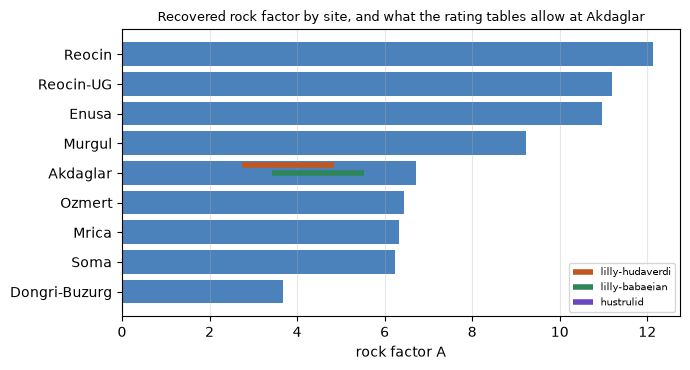

In [6]:
# Recovered factor per site, with the rating-table ranges for Akdaglar
order = sorted(bf.SITE_ROCK_FACTOR, key=bf.SITE_ROCK_FACTOR.get)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(order, [bf.SITE_ROCK_FACTOR[s] for s in order], color="#2b6cb0", alpha=0.85)
row = order.index("Akdaglar")
colors = {"lilly-hudaverdi": "#c05621", "lilly-babaeian": "#2f855a", "hustrulid": "#6b46c1"}
for k, (scheme, (low, high, _)) in enumerate(ranges.items()):
    ax.plot([low, high], [row + 0.25 - 0.25 * k] * 2, color=colors[scheme], lw=4, solid_capstyle="butt", label=scheme)
ax.set_xlabel("rock factor A")
ax.set_title("Recovered rock factor by site, and what the rating tables allow at Akdaglar")
ax.title.set_fontsize(9)
ax.legend(fontsize=7, loc="lower right")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

## Results

**The inversion reproduces the engine's table.** Recomputing the factor from the printed 2012 predictions gives the pinned value of every site to two decimals. Inside a site the recovered factor barely moves (a spread of a few percent at most, and zero at the sites with a single usable blast), which is what rounding the printed predictions to two decimals produces. Between sites it runs from under 4 to over 12, so the rock, not the arithmetic, carries the variation.

**The two papers disagree, and the disagreement is a result.** The 2010 column implies factors about 9 percent larger than the 2012 column. They are different published numbers for the same blasts, so the engine pins the 2012 column, the table that carries all three published arms, and never mixes the two.

**The rating tables do not pin the factor.** For the one site where the corpus describes the rock, the Lilly schemes span a wide band (depending on two categories this corpus does not record) and neither reaches the recovered value; the Hustrulid lookup returns a single value close to it. The tables disagree with each other by as much as they disagree with the data. That is why the product ships the recovered factors, and says in every prediction that they are derived.

**What this does not show.** The recovered factors are derived from the published predictions of the very blasts the hold-outs contain, so the classical arm that uses them carries knowledge of the site it is scored on. The next notebooks measure how much of the classical score is borrowed that way.

## Summary

- The classical equation is linear in the rock factor, so a published prediction fixes it; inverting the 2012 column reproduces the engine's nine pinned factors.
- The recovered factor is nearly constant inside a site, which validates the geometry, and spans a threefold range between sites.
- The 2010 and 2012 columns imply different factors; the engine pins one and never mixes them.
- Rating tables cannot pin the factor on this corpus: they need categories the corpus does not record and disagree with each other.
- Next: notebook 03 compares the engine's classical arms with the published hold-out tables (level 3).

## References

- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (Eqs. 1 to 3, the 2010 classical column)
- Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (the 2012 hold-out and its classical column)
- Babaeian et al. 2019, https://doi.org/10.1016/j.jrmge.2018.11.006 (Tables 1 and 2, the second rating table and the Hustrulid lookup)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/